# Data transformers

In [143]:
import pandas as pd


df = pd.read_csv('comments.csv')
df.head()

,comment,toxic
0,"Верблюдов-то за что? Дебилы, бл...\n",1.0
1,"Хохлы, это отдушина затюканого россиянина, мол...",1.0
2,Собаке - собачья смерть\n,1.0
3,"Страницу обнови, дебил. Это тоже не оскорблени...",1.0
4,"тебя не убедил 6-страничный пдф в том, что Скр...",1.0


In [144]:
%%capture cap --no-stderr
!pip install pymorphy3
import pymorphy3
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')
from nltk import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from nltk.util import ngrams
import re

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [145]:
from sklearn.base import BaseEstimator, TransformerMixin


class LemmatizeTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        self.morph = pymorphy3.MorphAnalyzer()
        self.stopwords = stopwords.words("russian") + ['это', 'её', '']
        return self

    def transform(self, X):
        def clean_text(text):
            text = text.lower()
            text = re.sub(r'http\S+', '', text)
            text = re.sub(r'www\S+', '', text)
            text = re.sub(r"\'s", " ", text)
            text = re.sub('\W', ' ', text)
            text = re.sub('\s+', ' ', text)
            text = text.strip(' ')
            return text


        X_copy = X.copy()

        X_copy['comment'] = X_copy['comment'].apply(clean_text)
        X_copy['comment'] = X_copy['comment'].apply(lambda x: list(map(lambda word: self.morph.parse(word)[0].normal_form, word_tokenize(x))))
        X_copy['comment'] = X_copy['comment'].apply(lambda x: [word for word in x if word not in self.stopwords])
        X_copy['comment'] = X_copy['comment'].apply(lambda x: ' '.join(x))

        return X_copy

In [148]:
lemmatizer = LemmatizeTransformer()
lemmatizer.fit(df)
df = lemmatizer.transform(df)
df

,comment,toxic
0,верблюд дебил бл,1.0
1,хохол отдушина затюканый россиянин мол вон хох...,1.0
2,собака собачий смерть,1.0
3,страница обновить дебил оскорбление доказать ф...,1.0
4,убедить 6 страничный пдф скрипаль отравить рос...,1.0
...,...,...
14407,вонючий совковый скот прибежать ныть сторонник...,1.0
14408,любить гоблин тупорылый нибыть продажный сука ...,1.0
14409,посмотреть утомлённый солнце 2 оказаться хорош...,0.0
14410,крымотред нарушать правило раздел немой обсужд...,1.0


In [152]:
df = df[df['comment'] != '']

In [153]:
df.isna().value_counts()

,,count
comment,toxic,
False,False,14411


In [154]:
df.to_csv('comments_lemmatized.csv')

# BoW + LogisticRegression [roc-auc 0.9162]

In [157]:
df = pd.read_csv('comments_lemmatized.csv', index_col=0)

In [208]:
from sklearn.model_selection import train_test_split


RANDOM_STATE=42


X = df.drop(columns=['toxic'])
y = df['toxic']
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, random_state=RANDOM_STATE, test_size=0.25)

In [209]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns


class CountTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        assert X.shape[1] == 1
        self.vectorizer_ = CountVectorizer()
        self.vectorizer_.fit(X[X.columns[0]])
        return self

    def transform(self, X):
        assert X.shape[1] == 1
        return self.vectorizer_.transform(X[X.columns[0]])


def get_metrics(y_true, y_pred, title=None):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(3, 3))

    ax = sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap=sns.color_palette("pastel", 5))
    ax.set_xlabel("Predicted", labelpad=20)
    ax.set_ylabel("Actual", labelpad=20)
    if title:
        ax.set_title(title)
    plt.show()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')

    print(f'accuracy:\t{accuracy}')
    print(f'precision:\t{precision}')
    print(f'recall:\t\t{recall}')
    print(f'f1:\t\t{f1}')

In [210]:
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


count_transformer = Pipeline(steps=[
    ('count_transformer', CountTransformer())
])

comment_transformer = ColumnTransformer(transformers=[
    ('comments', count_transformer, ['comment'])
])

preprocessor = Pipeline(steps=[('comment_transformer', comment_transformer)])

lr_pipeline = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('model', LogisticRegression())])


lr_pipeline.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('comment_transformer',
                                  ColumnTransformer(transformers=[('comments',
                                                                   Pipeline(steps=[('count_transformer',
                                                                                    CountTransformer())]),
                                                                   ['comment'])]))])),
                ('model', LogisticRegression())])

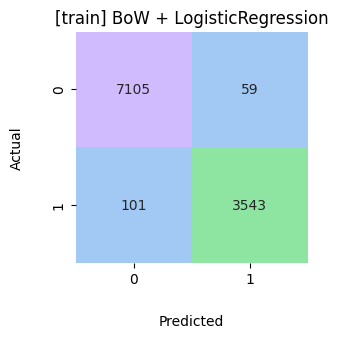

accuracy:	0.9851961509992598
precision:	0.9851869656703359
recall:		0.9851961509992598
f1:		0.9851748812311878


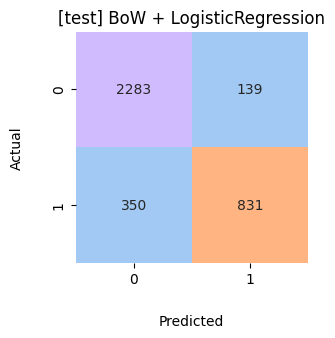

accuracy:	0.8642797668609492
precision:	0.8636724317747787
recall:		0.8642797668609492
f1:		0.8604556416968637


In [255]:
y_pred = lr_pipeline.predict(Xtrain)
get_metrics(ytrain, y_pred, '[train] BoW + LogisticRegression')
y_pred = lr_pipeline.predict(Xtest)
get_metrics(ytest, y_pred, '[test] BoW + LogisticRegression')

In [213]:
from sklearn.metrics import roc_auc_score


y_prob = lr_pipeline.predict_proba(Xtrain)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = lr_pipeline.predict_proba(Xtest)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.9983837577324358
roc_auc/test:	0.916262932713183


# Boosting [roc-auc 0.8756], Bagging [roc-auc 0.8913]

##  RandomForest

In [252]:
from sklearn.ensemble import RandomForestClassifier


count_transformer = Pipeline(steps=[
    ('count_transformer', CountTransformer())
])

comment_transformer = ColumnTransformer(transformers=[
    ('comments', count_transformer, ['comment'])
])

preprocessor = Pipeline(steps=[('comment_transformer', comment_transformer)])

rf_pipeline = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('model', RandomForestClassifier(random_state=RANDOM_STATE))])


rf_pipeline.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('comment_transformer',
                                  ColumnTransformer(transformers=[('comments',
                                                                   Pipeline(steps=[('count_transformer',
                                                                                    CountTransformer())]),
                                                                   ['comment'])]))])),
                ('model', RandomForestClassifier(random_state=42))])

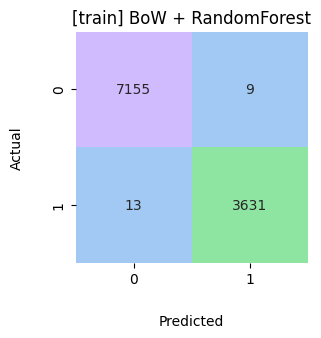

accuracy:	0.9979644707623982
precision:	0.9979642269017761
recall:		0.9979644707623982
f1:		0.9979641959119185


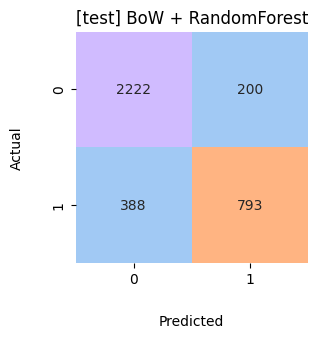

accuracy:	0.8368026644462948
precision:	0.834050190766748
recall:		0.8368026644462948
f1:		0.8327948927873798


In [256]:
y_pred = rf_pipeline.predict(Xtrain)
get_metrics(ytrain, y_pred, '[train] BoW + RandomForest')
y_pred = rf_pipeline.predict(Xtest)
get_metrics(ytest, y_pred, '[test] BoW + RandomForest')

In [260]:
y_prob = rf_pipeline.predict_proba(Xtrain)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = rf_pipeline.predict_proba(Xtest)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.9999894275622533
roc_auc/test:	0.8989647186984117


### hyperparameters

In [265]:
ct = CountTransformer()
ct.fit(Xtrain)
Xtrain_ = ct.transform(Xtrain)
Xtest_ = ct.transform(Xtest)

In [286]:
import numpy as np
from sklearn.model_selection import GridSearchCV


params = {
    'n_estimators': np.arange(10, 200, 20),
    'max_depth': list(np.arange(2, 21, 3)) + [None],
}

clf = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), params, cv=3, verbose=2, scoring='roc_auc')
clf.fit(Xtrain_, ytrain)

Fitting 3 folds for each of 80 candidates, totalling 240 fits
[CV] END .......................max_depth=2, n_estimators=10; total time=   0.1s
[CV] END .......................max_depth=2, n_estimators=10; total time=   0.1s
[CV] END .......................max_depth=2, n_estimators=10; total time=   0.1s
[CV] END .......................max_depth=2, n_estimators=30; total time=   0.1s
[CV] END .......................max_depth=2, n_estimators=30; total time=   0.2s
[CV] END .......................max_depth=2, n_estimators=30; total time=   0.2s
[CV] END .......................max_depth=2, n_estimators=50; total time=   0.4s
[CV] END .......................max_depth=2, n_estimators=50; total time=   0.4s
[CV] END .......................max_depth=2, n_estimators=50; total time=   0.4s
[CV] END .......................max_depth=2, n_estimators=70; total time=   0.5s
[CV] END .......................max_depth=2, n_estimators=70; total time=   0.5s
[CV] END .......................max_depth=2, n_

GridSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [2, 5, 8, 11, 14, 17, 20, None],
                         'n_estimators': array([ 10,  30,  50,  70,  90, 110, 130, 150, 170, 190])},
             scoring='roc_auc', verbose=2)

In [287]:
best_params = clf.best_params_
clf.best_score_, clf.best_estimator_, best_params

(0.897113731110572,
 RandomForestClassifier(max_depth=20, n_estimators=190, random_state=42),
 {'max_depth': 20, 'n_estimators': 190})

In [288]:
rf = RandomForestClassifier(random_state=RANDOM_STATE, **best_params)
rf.fit(Xtrain_, ytrain)

RandomForestClassifier(max_depth=20, n_estimators=190, random_state=42)

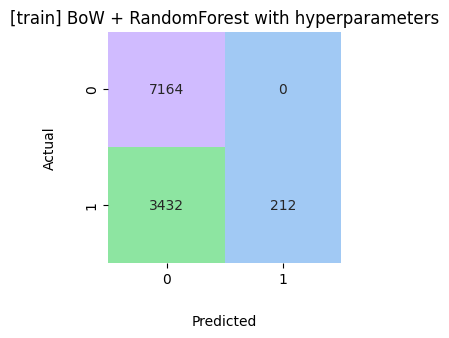

accuracy:	0.6824574389341229
precision:	0.7853081438773176
recall:		0.6824574389341229
f1:		0.5718258884239362


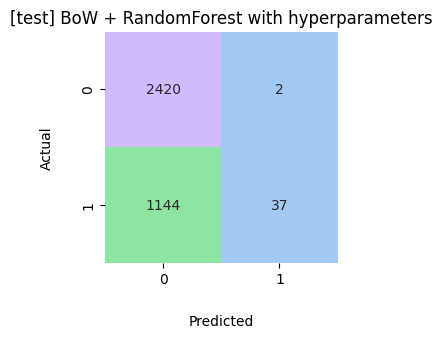

accuracy:	0.6819317235636969
precision:	0.767417096494717
recall:		0.6819317235636969
f1:		0.5634056333781431


In [289]:
y_pred = rf.predict(Xtrain_)
get_metrics(ytrain, y_pred, '[train] BoW + RandomForest with hyperparameters')
y_pred = rf.predict(Xtest_)
get_metrics(ytest, y_pred, '[test] BoW + RandomForest with hyperparameters')

In [290]:
y_prob = rf.predict_proba(Xtrain_)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = rf.predict_proba(Xtest_)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.9531746732197394
roc_auc/test:	0.8913921287436433


## GradientBoosting

In [291]:
from sklearn.ensemble import GradientBoostingClassifier


gb = GradientBoostingClassifier(random_state=RANDOM_STATE)
gb.fit(Xtrain_, ytrain)

GradientBoostingClassifier(random_state=42)

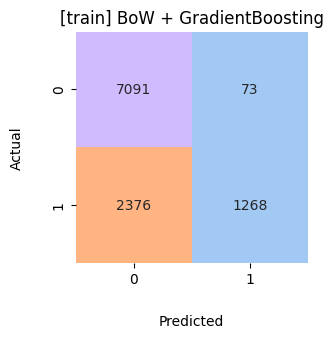

accuracy:	0.7734085862324205
precision:	0.8152879190835995
recall:		0.7734085862324205
f1:		0.7367563353199219


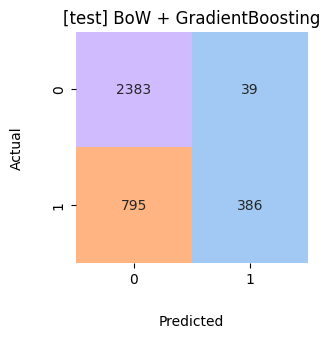

accuracy:	0.768526228143214
precision:	0.8017609839256783
recall:		0.768526228143214
f1:		0.7296693342928215


In [292]:
y_pred = gb.predict(Xtrain_)
get_metrics(ytrain, y_pred, '[train] BoW + GradientBoosting')
y_pred = gb.predict(Xtest_)
get_metrics(ytest, y_pred, '[test] BoW + GradientBoosting')

In [293]:
y_prob = gb.predict_proba(Xtrain_)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = gb.predict_proba(Xtest_)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.8533927718847929
roc_auc/test:	0.8182882566034886


In [295]:
import numpy as np
from sklearn.model_selection import GridSearchCV


params = {
    'n_estimators': np.arange(10, 200, 20),
    'max_depth': [2, 4, 6],
}

clf = GridSearchCV(GradientBoostingClassifier(random_state=RANDOM_STATE), params, cv=3, verbose=2, scoring='roc_auc')
clf.fit(Xtrain_, ytrain)

Fitting 3 folds for each of 30 candidates, totalling 90 fits
[CV] END .......................max_depth=2, n_estimators=10; total time=   2.0s
[CV] END .......................max_depth=2, n_estimators=10; total time=   2.5s
[CV] END .......................max_depth=2, n_estimators=10; total time=   2.6s
[CV] END .......................max_depth=2, n_estimators=30; total time=   5.8s
[CV] END .......................max_depth=2, n_estimators=30; total time=   7.1s
[CV] END .......................max_depth=2, n_estimators=30; total time=   5.9s
[CV] END .......................max_depth=2, n_estimators=50; total time=  10.9s
[CV] END .......................max_depth=2, n_estimators=50; total time=  11.0s
[CV] END .......................max_depth=2, n_estimators=50; total time=  11.1s
[CV] END .......................max_depth=2, n_estimators=70; total time=  14.7s
[CV] END .......................max_depth=2, n_estimators=70; total time=  14.9s
[CV] END .......................max_depth=2, n_e

GridSearchCV(cv=3, estimator=GradientBoostingClassifier(random_state=42),
             param_grid={'max_depth': [2, 4, 6],
                         'n_estimators': array([ 10,  30,  50,  70,  90, 110, 130, 150, 170, 190])},
             scoring='roc_auc', verbose=2)

In [296]:
best_params = clf.best_params_
clf.best_score_, clf.best_estimator_, best_params

(0.8724706451469193,
 GradientBoostingClassifier(max_depth=6, n_estimators=190, random_state=42),
 {'max_depth': 6, 'n_estimators': 190})

In [297]:
gb = GradientBoostingClassifier(random_state=RANDOM_STATE, **best_params)
gb.fit(Xtrain_, ytrain)

GradientBoostingClassifier(max_depth=6, n_estimators=190, random_state=42)

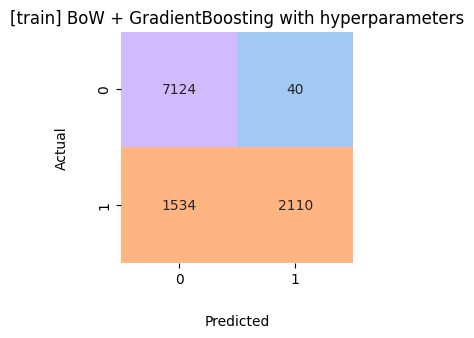

accuracy:	0.8543671354552184
precision:	0.8762867647914038
recall:		0.8543671354552184
f1:		0.8424669303128924


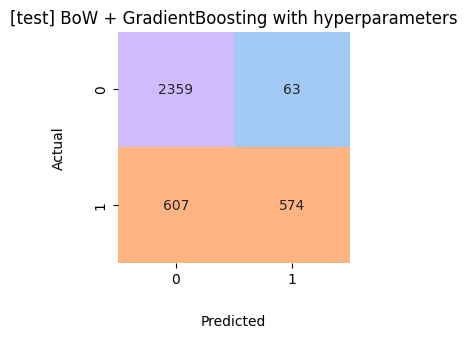

accuracy:	0.8140438523452679
precision:	0.8300107931820773
recall:		0.8140438523452679
f1:		0.7956095717066884


In [298]:
y_pred = gb.predict(Xtrain_)
get_metrics(ytrain, y_pred, '[train] BoW + GradientBoosting with hyperparameters')
y_pred = gb.predict(Xtest_)
get_metrics(ytest, y_pred, '[test] BoW + GradientBoosting with hyperparameters')

In [299]:
y_prob = clf.predict_proba(Xtrain_)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = clf.predict_proba(Xtest_)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.9524247004935643
roc_auc/test:	0.8756281503659302


# BERT [roc-auc 0.93402]

In [300]:
df_train = pd.concat([Xtrain, ytrain.astype(int)], axis=1)
df_train

,comment,toxic
5049,козырёк второй фотка дешёвый сайдинг обшить вп...,1
4192,переключение поле ввод кнопка прочий интеракти...,0
10606,вокзал таксист очень сильно ценник упасть дешё...,0
9186,сколько угодный гундеть 43 маленький 50 любой ...,0
9971,запредельный цена питер москва лоукостер долет...,0
...,...,...
5191,знать откуда машина столько человек район новы...,0
13419,всё кроме тигр похожий обычный дворовый кот,0
5390,второй сезон полный хует,0
860,мда хотеть просто спасибо сказать обижёнка зад...,1


In [301]:
from torch.utils.data import Dataset


class TextClassificationDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]
        encoding = self.tokenizer(text, return_tensors='pt', max_length=self.max_length, padding='max_length', truncation=True)
        return {'input_ids': encoding['input_ids'].flatten(), 'attention_mask': encoding['attention_mask'].flatten(), 'label': torch.tensor(label)}

In [302]:
import torch
from torch import nn
from transformers import BertModel

class BERTClassifier(nn.Module):
    def __init__(self, bert_model_name, num_classes):
        super(BERTClassifier, self).__init__()
        self.bert = BertModel.from_pretrained(bert_model_name)
        self.dropout = nn.Dropout(0.1)
        self.fc = nn.Linear(self.bert.config.hidden_size, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        pooled_output = outputs.pooler_output
        x = self.dropout(pooled_output)
        logits = self.fc(x)
        return logits

In [303]:
import os
from torch.utils.data import DataLoader
from transformers import BertTokenizer, get_linear_schedule_with_warmup
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, classification_report
from tqdm import tqdm


def train(model, data_loader, optimizer, scheduler, device):
    model.train()
    for batch in tqdm(data_loader):
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        loss = nn.CrossEntropyLoss()(outputs, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()


def evaluate(model, data_loader, device):
    model.eval()
    predictions = []
    actual_labels = []
    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            _, preds = torch.max(outputs, dim=1)
            predictions.extend(preds.cpu().tolist())
            actual_labels.extend(labels.cpu().tolist())
    return accuracy_score(actual_labels, predictions), classification_report(actual_labels, predictions)

In [304]:
features = ['comment', 'toxic']
texts = df_train['comment'].tolist()
labels = df_train['toxic'].tolist()


bert_model_name = 'cointegrated/rubert-tiny'
num_classes = 2
max_length = 128
batch_size = 16
num_epochs = 4
learning_rate = 2e-5

train_texts, val_texts, train_labels, val_labels = train_test_split(texts, labels, test_size=0.2, random_state=RANDOM_STATE)

tokenizer = BertTokenizer.from_pretrained(bert_model_name)
train_dataset = TextClassificationDataset(train_texts, train_labels, tokenizer, max_length)
val_dataset = TextClassificationDataset(val_texts, val_labels, tokenizer, max_length)
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = BERTClassifier(bert_model_name, num_classes).to(device)

optimizer = AdamW(model.parameters(), lr=learning_rate)
total_steps = len(train_dataloader) * num_epochs
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)

for epoch in range(num_epochs):
    print(f"Epoch {epoch + 1}/{num_epochs}")
    train(model, train_dataloader, optimizer, scheduler, device)
    accuracy, report = evaluate(model, val_dataloader, device)
    print(f"Validation Accuracy: {accuracy:.4f}")
    print(report)

Epoch 1/4


100%|██████████| 541/541 [09:05<00:00,  1.01s/it]


Validation Accuracy: 0.8432
              precision    recall  f1-score   support

           0       0.90      0.86      0.88      1436
           1       0.74      0.82      0.78       726

    accuracy                           0.84      2162
   macro avg       0.82      0.84      0.83      2162
weighted avg       0.85      0.84      0.84      2162

Epoch 2/4


100%|██████████| 541/541 [09:03<00:00,  1.01s/it]


Validation Accuracy: 0.8626
              precision    recall  f1-score   support

           0       0.91      0.89      0.90      1436
           1       0.78      0.82      0.80       726

    accuracy                           0.86      2162
   macro avg       0.84      0.85      0.85      2162
weighted avg       0.86      0.86      0.86      2162

Epoch 3/4


100%|██████████| 541/541 [09:00<00:00,  1.00it/s]


Validation Accuracy: 0.8636
              precision    recall  f1-score   support

           0       0.90      0.89      0.90      1436
           1       0.79      0.80      0.80       726

    accuracy                           0.86      2162
   macro avg       0.85      0.85      0.85      2162
weighted avg       0.86      0.86      0.86      2162

Epoch 4/4


100%|██████████| 541/541 [09:03<00:00,  1.00s/it]


Validation Accuracy: 0.8677
              precision    recall  f1-score   support

           0       0.90      0.90      0.90      1436
           1       0.81      0.80      0.80       726

    accuracy                           0.87      2162
   macro avg       0.85      0.85      0.85      2162
weighted avg       0.87      0.87      0.87      2162



In [305]:
torch.save(model.state_dict(), f'rubert-tiny-e4.pth')

In [316]:
def predict(text, model, tokenizer, device, max_length=128):
    model.eval()
    encoding = tokenizer(text, return_tensors='pt', max_length=max_length, padding='max_length', truncation=True)
    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)
    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        _, preds = torch.max(outputs, dim=1)
    return 1 if preds.item() == 1 else 0


ypred = []
for comment in tqdm(Xtest['comment']):
    ypred.append(predict(comment, model, tokenizer, device))

100%|██████████| 3603/3603 [01:18<00:00, 45.62it/s]


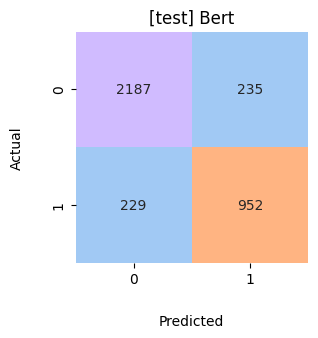

accuracy:	0.8712184290868721
precision:	0.871390274761857
recall:		0.8712184290868721
f1:		0.8713017251286655


In [307]:
get_metrics(ytest, ypred, '[test] Bert')

In [317]:
def predict_proba(text, model, tokenizer, device, max_length=128):
    model.eval()
    encoding = tokenizer(text, return_tensors='pt', max_length=max_length, padding='max_length', truncation=True)
    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)
    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.softmax(outputs, dim=1)
    return preds[:, 1].item()


y_prob = []
for comment in tqdm(Xtest['comment']):
    y_prob.append(predict_proba(comment, model, tokenizer, device))
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

100%|██████████| 3603/3603 [01:18<00:00, 45.79it/s]

roc_auc/test:	0.934020001524272
